In [ ]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

In [ ]:
import torch

import numpy as np
import pandas as pd

import umap
import matplotlib.pyplot as plt

from deep_models.lib_models import ConvVAE, BagVariationalEncoder, load_folds, make_splits, read_from_summary, extract, active_units
from lib_linear_probing_lightning import mu_encoder, active_mask,  select_dims, encode_raw_bags, run_nn_probes, plot_embedding_votes
from sklearn.decomposition import PCA

https://apxml.com/courses/applied-autoencoders-feature-extraction/chapter-7-applying-autoencoder-features-practical-guidance/tuning-hyperparameters-optimal-performance

In [2]:
run_name = "convvae_l256_k3s2p1_h32-64_bn1_bs10_mi150_beta0.01_ann50"
out_dir = f"results_s00/{run_name}"
dev_path = "splits/s00_developmental.npz"

split_k = 9                        # AE split: test fold = k, val fold = k+1, rest = train
seed = 42

hyperparameters, checkpoint_model = read_from_summary(out_dir, split_k)

In [3]:
representations = ["trained_vae", 
                   "trained_vae_active", 
                   "untrained_vae", 
                   "pca", 
                   "raw"]

In [4]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1077  val=136  test=140


In [5]:
splits = [("train", train_idx), 
          ("val", val_idx), 
          ("test", test_idx)]

raw = {n: extract(i) for n, i in splits} 
y_train, y_val, y_test = raw["train"][1], raw["val"][1], raw["test"][1]

print("pathology rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

pathology rate  train/val/test: 0.467 0.529 0.521


In [6]:
def build_ae(hyperparameters):
    return ConvVAE(latent=hyperparameters["latent"], 
                   kernel=hyperparameters["kernel"], 
                   strides=hyperparameters["strides"],
                   padding=hyperparameters["padding"], 
                   batchnorm=hyperparameters["batchnorm"], 
                   hidden=hyperparameters["hidden"])      

In [7]:
trained_vae = BagVariationalEncoder.load_from_checkpoint(checkpoint_model, 
                                                         ae=build_ae(hyperparameters), 
                                                         map_location="cpu").eval()


In [8]:
torch.manual_seed(seed)                      
random_vae = build_ae(hyperparameters).eval()  

In [9]:
bags = {"raw": {n: raw[n][0] for n in raw}}
for name, encoder in [("trained_vae", mu_encoder(trained_vae.ae)),
                      ("untrained_vae", mu_encoder(random_vae))]:
        bags[name] = {n: extract(i, encoder)[0] for n, i in splits}

In [10]:
mu_trained, logvar_trained = encode_raw_bags(trained_vae.ae, bags["raw"]["val"])
mu_random, logvar_random = encode_raw_bags(random_vae, bags["raw"]["val"])

In [11]:
for name, (mu, logvar) in {"trained": (mu_trained, logvar_trained), 
                            "random": (mu_random, logvar_random)}.items():
    
    n_active_units, var_mu, kl_dim = active_units(mu, logvar)
    print(f"{name}: {n_active_units}/{mu.shape[-1]} active | total KL {kl_dim.sum():.1f} nats")

trained: 15/256 active | total KL 9.9 nats
random: 0/256 active | total KL 0.1 nats


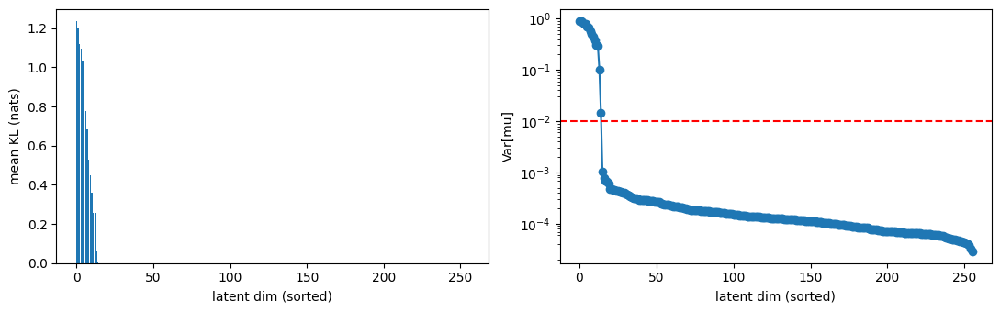

In [12]:
n_act, var_mu, kl_dim = active_units(mu_trained, logvar_trained)
order = np.argsort(kl_dim)[::-1]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(len(kl_dim)), kl_dim[order])
ax[0].set(xlabel="latent dim (sorted)",
          ylabel="mean KL (nats)")

ax[1].semilogy(np.sort(var_mu)[::-1], "o-")
ax[1].axhline(0.01, c="r", ls="--")
ax[1].set(xlabel="latent dim (sorted)", ylabel="Var[mu]")
plt.tight_layout()

In [13]:
mask = active_mask(bags["trained_vae"]["train"])
bags["trained_vae_active"] = select_dims(bags["trained_vae"], mask)

In [14]:
pca = PCA(n_components=hyperparameters["latent"], random_state=seed).fit(np.concatenate(bags["raw"]["train"]))
bags["pca"] = {n: [pca.transform(b) for b in bl] for n, bl in bags["raw"].items()}

In [15]:
for representation, data_part in bags.items():
    print(f"{representation:7s} bag shape (windows, dim) = {data_part['train'][0].shape}")

raw     bag shape (windows, dim) = (150, 1445)
trained_vae bag shape (windows, dim) = (150, 256)
untrained_vae bag shape (windows, dim) = (150, 256)
trained_vae_active bag shape (windows, dim) = (150, 15)
pca     bag shape (windows, dim) = (150, 256)


In [16]:
reducer = umap.UMAP(random_state = 42)

In [17]:
val_instances_trained = np.concatenate(bags["trained_vae"]["val"], axis = 0)
val_instances_trained_active = np.concatenate(bags["untrained_vae"]["val"], axis = 0)
val_instances_untrained = np.concatenate(bags["trained_vae_active"]["val"], axis = 0)
val_instances_raw = np.concatenate(bags["raw"]["val"], axis = 0)
val_instances_pca = np.concatenate(bags["pca"]["val"], axis = 0)

In [18]:
val_bags = bags["trained_vae"]["val"]
exam_ids = np.repeat(np.arange(len(val_bags)), [len(bag) for bag in val_bags])
bag_sizes = [len(bag) for bag in val_bags]
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

In [19]:
val_bags = bags["trained_vae"]["val"]
exam_ids = np.repeat(np.arange(len(val_bags)), [len(bag) for bag in val_bags])
bag_sizes = [len(bag) for bag in val_bags]
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

embeddings = {
    "trained vae":   reducer.fit_transform(val_instances_trained),
    "trained_vae_active": reducer.fit_transform(val_instances_trained_active),
    "untrained vae": reducer.fit_transform(val_instances_untrained),
    "raw":       reducer.fit_transform(val_instances_raw),
    "pca on raw":       reducer.fit_transform(val_instances_pca),
}

In [20]:
rows, artifacts = run_nn_probes(bags, representations, y_train, y_val, y_test,
                    lr=1e-3,
                    batch_size=100,
                    max_epochs=200,
                    return_artifacts = True)

[trained_vae] LinearBagProbe  val AUC = 0.688  epoch = 139  test AUC = 0.600
[trained_vae] LinearInstanceProbeBagLabels_soft  val AUC = 0.682  epoch = 35  test AUC = 0.566
[trained_vae] LinearInstanceProbeBagLabels_vote  val AUC = 0.670  epoch = 35  test AUC = 0.564
[trained_vae] ABMIL_linear  val AUC = 0.667  epoch = 6  test AUC = 0.666
[trained_vae] ABMIL_h64  val AUC = 0.688  epoch = 14  test AUC = 0.672
[trained_vae_active] LinearBagProbe  val AUC = 0.651  epoch = 104  test AUC = 0.626
[trained_vae_active] LinearInstanceProbeBagLabels_soft  val AUC = 0.647  epoch = 7  test AUC = 0.632
[trained_vae_active] LinearInstanceProbeBagLabels_vote  val AUC = 0.633  epoch = 7  test AUC = 0.628
[trained_vae_active] ABMIL_linear  val AUC = 0.621  epoch = 12  test AUC = 0.663
[trained_vae_active] ABMIL_h64  val AUC = 0.670  epoch = 2  test AUC = 0.594
[untrained_vae] LinearBagProbe  val AUC = 0.751  epoch = 71  test AUC = 0.704
[untrained_vae] LinearInstanceProbeBagLabels_soft  val AUC = 0.716 

In [21]:
res_df = pd.DataFrame(rows).set_index(["Representation", "Method"])
res_df
#res_df.to_csv(f"{out_dir}/probe_results/{split_k}.csv", index = False)

Val AUC  Epoch  \
Representation     Method                                               
trained_vae        LinearBagProbe                     0.687934    139   
                   LinearInstanceProbeBagLabels_soft  0.681641     35   
                   LinearInstanceProbeBagLabels_vote  0.669813     35   
                   ABMIL_linear                       0.667318      6   
                   ABMIL_h64                          0.687934     14   
trained_vae_active LinearBagProbe                     0.650825    104   
                   LinearInstanceProbeBagLabels_soft  0.647135      7   
                   LinearInstanceProbeBagLabels_vote  0.633355      7   
                   ABMIL_linear                       0.620660     12   
                   ABMIL_h64                          0.670139      2   
untrained_vae      LinearBagProbe                     0.751302     71   
                   LinearInstanceProbeBagLabels_soft  0.715712     33   
                   LinearInstanceProbeBagLabels_vote  0.732530     33   
                   ABMIL_linear                       0.680122      4   
                   ABMIL_h64                          0.707031      2   
pca                LinearBagProbe                     0.731554      8   
                   LinearInstanceProbeBagLabels_soft  0.722439     12   
                   LinearInstanceProbeBagLabels_vote  0.719401     12   
                   ABMIL_linear                       0.724175      1   
                   ABMIL_h64                          0.702908      3   
raw                LinearBagProbe                     0.744575     46   
                   LinearInstanceProbeBagLabels_soft  0.742405     59   
                   LinearInstanceProbeBagLabels_vote  0.739149     59   
                   ABMIL_linear                       0.734158      6   
                   ABMIL_h64                          0.754774     28   

                                                      Test AUC  Seed  
Representation     Method                                             
trained_vae        LinearBagProbe                     0.600491   NaN  
                   LinearInstanceProbeBagLabels_soft  0.565529   NaN  
                   LinearInstanceProbeBagLabels_vote  0.563995   NaN  
                   ABMIL_linear                       0.666121   0.0  
                   ABMIL_h64                          0.672051   0.0  
trained_vae_active LinearBagProbe                     0.626457   NaN  
                   LinearInstanceProbeBagLabels_soft  0.631773   NaN  
                   LinearInstanceProbeBagLabels_vote  0.627990   NaN  
                   ABMIL_linear                       0.663055   0.0  
                   ABMIL_h64                          0.594357   0.0  
untrained_vae      LinearBagProbe                     0.703946   NaN  
                   LinearInstanceProbeBagLabels_soft  0.661623   NaN  
                   LinearInstanceProbeBagLabels_vote  0.677878   NaN  
                   ABMIL_linear                       0.677367   0.0  
                   ABMIL_h64                          0.678798   0.0  
pca                LinearBagProbe                     0.602126   NaN  
                   LinearInstanceProbeBagLabels_soft  0.627479   NaN  
                   LinearInstanceProbeBagLabels_vote  0.664077   NaN  
                   ABMIL_linear                       0.600286   0.0  
                   ABMIL_h64                          0.605193   0.0  
raw                LinearBagProbe                     0.654467   NaN  
                   LinearInstanceProbeBagLabels_soft  0.608669   NaN  
                   LinearInstanceProbeBagLabels_vote  0.627275   NaN  
                   ABMIL_linear                       0.628501   0.0  
                   ABMIL_h64                          0.693314   0.0

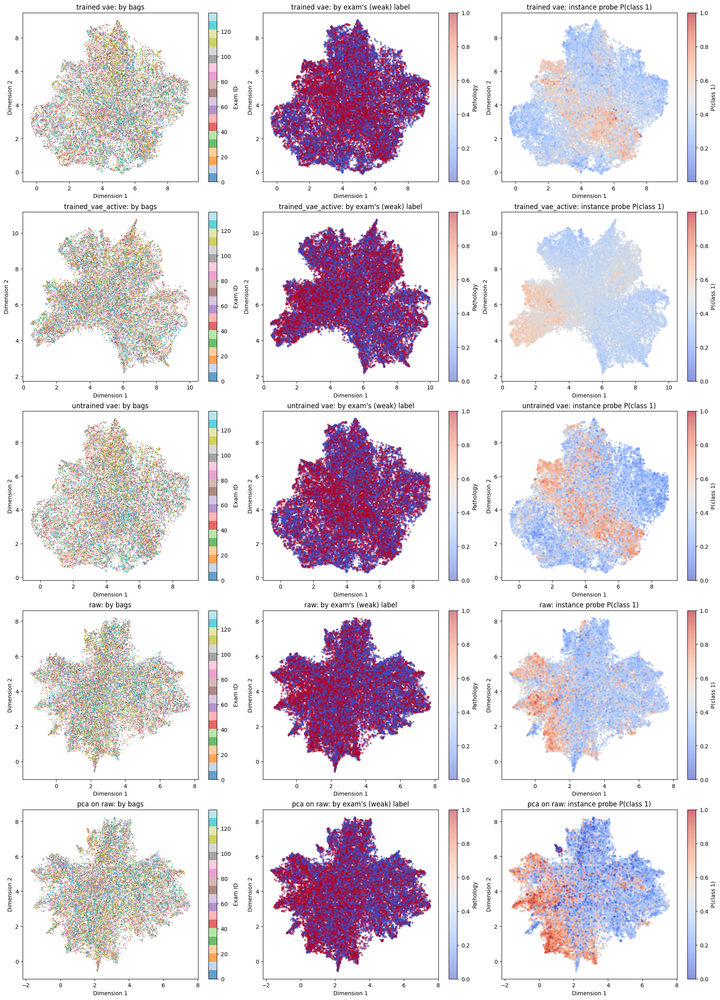

In [22]:
plot_embedding_votes(embeddings, artifacts, exam_ids, window_labels, rep_of=representations, mode = 'prob')
plt.show()

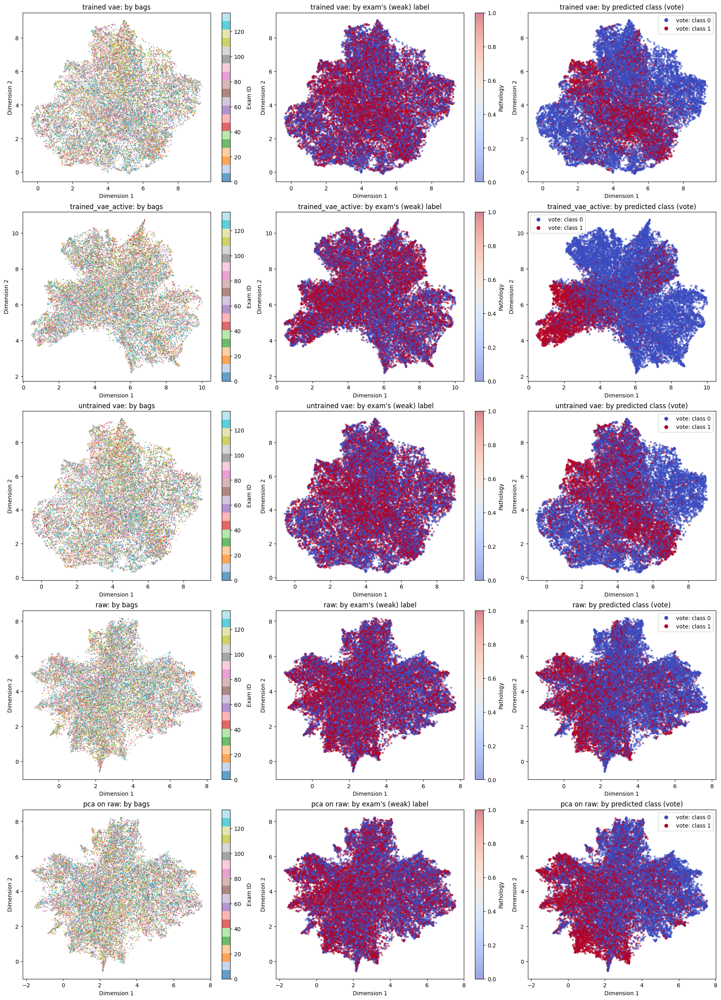

In [23]:
plot_embedding_votes(embeddings, artifacts, exam_ids, window_labels, rep_of=representations, mode = 'vote')              # probabilities                                                  
plt.show()